In [ ]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import scipy.stats as stats

github repo -- https://github.com/rmcelreath/stat_rethinking_2024
lecture -- https://www.youtube.com/watch?v=R1vcdhPBlXA&list=PLDcUM9US4XdPz-KxHM4XHt7uUVGWWVSus&index=2
slides -- https://speakerdeck.com/rmcelreath/statistical-rethinking-2023-lecture-02?slide=5
pymc translation -- https://github.com/pymc-devs/pymc-resources/blob/main/Rethinking_2/Chp_02.ipynb?short_path=08fe765


Move globe, is Land or is water, given that, what is proportion of water

proportion of water - p ; this is the Estimand
number of tosses - N
water observations - W
land observations - L

N influences W and L
meaning a change of N would change W and L
causal influences
an intervention of N would change W and L but not reverse

p influences W and L
p higher would mean W would be higher

W,L = $f(p, N)$

# essence of baynesian analysis

* For each possible explanation of the sample,
* Count all the ways the sample could happen.
* Explanations with more ways to produce the
sample are more plausible

# For this problem

* For each possible proportion
of water on the globe,
* Count all the ways the sample
of tosses could happen.
* Proportions with more ways
to produce the sample are
more plausible


Counting the number of ways we could have produced the same.

To produce water / land / water

Assuming p is 

* p=0 -- 0 ways
* p=25% -- 3 ways of 64 (1 way * 3 ways * 1 way)
* p=50% -- 8 ways of 64 (2 ways * 2 ways * 2 way)
* p=75% -- 9 ways of 64 (3 ways * 1 ways * 3 way)
* p=100% -- 0 ways




In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# now compute 
# 1 is water, 0 is land
sample = [1, 0, 1, 1, 1, 0, 1, 0, 1]

records = []

# imagine 4 side die
die_faces = 4
for land_possible in range(0, die_faces+1):
    water_possible = die_faces - land_possible 

    ways = 1
    for sample_value in sample:
        if sample_value == 1:
            ways *= water_possible
        else:
            ways *= land_possible

    #print(f"For water {water_possible} / land {land_possible} ways is {ways}")
    records.append({
        "water": water_possible,
        "land": land_possible,
        "proportion_water": water_possible / die_faces,
        "ways": ways
    })

df = pd.DataFrame(records)

# Normalise to obtain probabilities
df["prob"] = df["ways"] / df["ways"].sum()

df

,water,land,proportion_water,ways,prob
0,4,0,1.00,0,0.000000
1,3,1,0.75,729,0.574921
2,2,2,0.50,512,0.403785
3,1,3,0.25,27,0.021293
4,0,4,0.00,0,0.000000


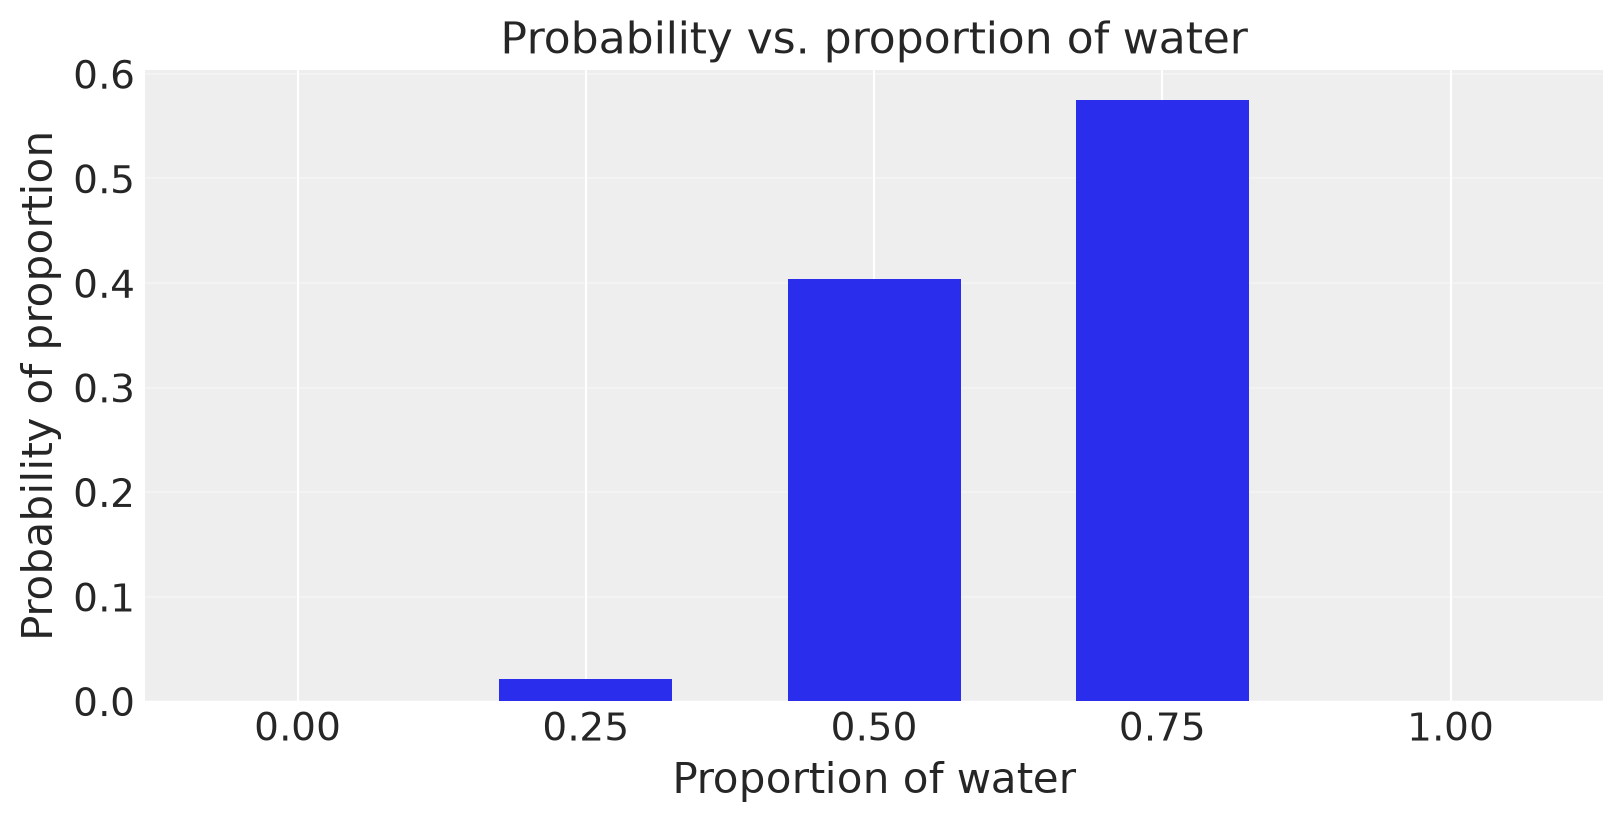

In [32]:
plt.figure(figsize=(8, 4))

plt.bar(df["proportion_water"], df["prob"], width=0.15)

plt.xlabel("Proportion of water")
plt.ylabel("Probability of proportion")
plt.title("Probability vs. proportion of water")
plt.xticks(df["proportion_water"])
plt.grid(axis="y", alpha=0.3)

# the y axis is the posterior distribution

plt.show()

Ways for p (0 to 1) to produce W,L = $ (4p)^W \times (4-4p)^L $ 

Probability: Non-negative values that sum to one

Suppose W=20, L=10. then p=0.5 has

$ 2W \times 2L = 1,073,741,824 $

ways to produce sample. Better to convert to probability.

In [5]:
import numpy as np
# Generative simulation
# https://speakerdeck.com/rmcelreath/statistical-rethinking-2023-lecture-02?slide=53
# https://youtu.be/R1vcdhPBlXA?t=2497
# for a given set of parameters, produces a sample
def sim_globe(p=0.7, N=9):
    """
    p: proportion of the globe covered by water. 0 <= p <= 1
    N: number of tosses.
    "W": water; "L": land.
    replace=True: each toss is independent.
    """
    return np.random.choice(
        ["W", "L"],
        size=N,
        p=[p, 1 - p],
        replace=True
    )

# Example
sample = sim_globe(p=0.7, N=9)
print(sample)

# tests
# known answer
print(sim_globe(p=1, N=11))
print(sim_globe(p=0, N=11))
# large N
print( sum( [v == 'W' for v in sim_globe(p=0.5, N=int(1e4)) ] ) / 1e4 )

['W' 'L' 'W' 'W' 'W' 'W' 'W' 'W' 'W']
['W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W']
['L' 'L' 'L' 'L' 'L' 'L' 'L' 'L' 'L' 'L' 'L']
0.4989


In [57]:
import numpy as np
import pandas as pd

def compute_posterior(the_sample, poss=(0, 0.25, 0.5, 0.75, 1)):
    """
    the_sample: list of ["W", "L", "W", etc.]
    poss: set of possibilities

    https://youtu.be/R1vcdhPBlXA?t=2562

    Aka the estimator
    """
    # Number of water and land observations
    W = np.sum(np.array(the_sample) == "W")
    L = np.sum(np.array(the_sample) == "L")

    # Number of ways each possible globe could produce the sample
    poss = np.array(poss)
    num_die_faces = len(poss) - 1
    ways = (poss * num_die_faces) ** W * ((1 - poss) * num_die_faces) ** L

    # Normalize to obtain posterior probabilities
    # this is the posterior distribution
    post = ways / ways.sum()

    # Visual representation of posterior probabilities
    max_bar_length = 30
    bars = [
        "█" * round(prob / post.max() * max_bar_length)
        for prob in post
    ]

    return pd.DataFrame({
        "proportion_water": poss,
        "ways": ways.astype(int),
        "post": np.round(post, 3),
        "bars": bars
    })


# Example
sample = sim_globe(p=0.1, N=3)

df = compute_posterior(sample)
display(df)

,proportion_water,ways,post,bars
0,0.00,64,0.64,██████████████████████████████
1,0.25,27,0.27,█████████████
2,0.50,8,0.08,████
3,0.75,1,0.01,
4,1.00,0,0.00,


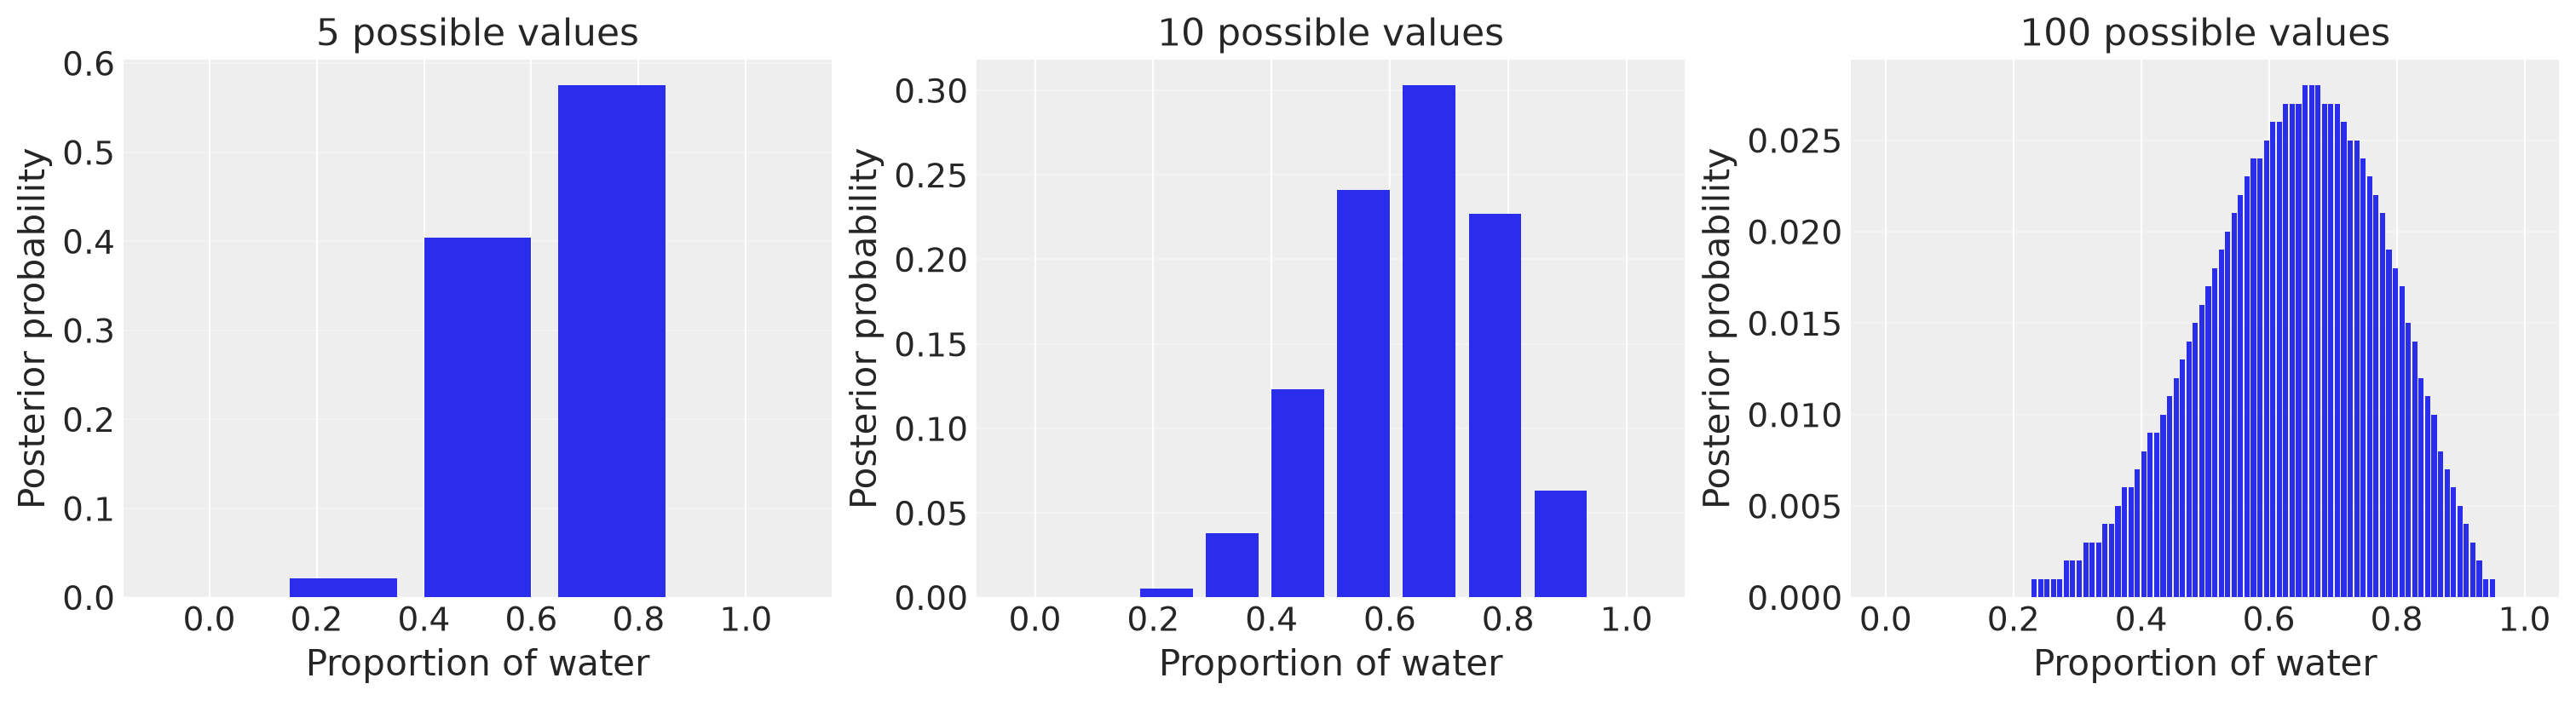

In [58]:
sample = ["W", "L", "W", "W", "W", "L", "W", "L", "W"]

def plot_df(df):
    plt.figure(figsize=(8, 4))

    plt.bar(df["proportion_water"], df["post"], width=0.15)

    plt.xlabel("Proportion of water")
    plt.ylabel("Probability of proportion")
    plt.title("Probability vs. proportion of water")
    plt.xticks(df["proportion_water"])
    plt.grid(axis="y", alpha=0.3)

    # the y axis is the posterior distribution

    plt.show()

# df = compute_posterior(sample, np.linspace(0, 1, 5))
# plot_df(df)
# df = compute_posterior(sample, np.linspace(0, 1, 10))
# plot_df(df)
# df = compute_posterior(sample, np.linspace(0, 1, 100))
# plot_df(df)

def plot_dfs(dfs, titles):
    fig, axes = plt.subplots(
        1, len(dfs),
        figsize=(15, 4),
        constrained_layout=True
    )

    for ax, df, title in zip(axes, dfs, titles):
        ax.bar(
            df["proportion_water"],
            df["post"],
            width=0.8 * (df["proportion_water"].iloc[1] -
                         df["proportion_water"].iloc[0])
        )

        ax.set_title(title)
        ax.set_xlabel("Proportion of water")
        ax.set_ylabel("Posterior probability")
        ax.grid(axis="y", alpha=0.3)

    plt.show()


dfs = [
    compute_posterior(sample, np.linspace(0, 1, 5)),
    compute_posterior(sample, np.linspace(0, 1, 10)),
    compute_posterior(sample, np.linspace(0, 1, 100))
]

titles = ["5 possible values", "10 possible values", "100 possible values"]

# notice how y axis gets lower because more bars means to sum to 1 

plot_dfs(dfs, titles)
#df

integration by parts formula
$$
\boxed{\int u\,dv=uv-\int v\,du}
\\

\tag{Definite version}

\boxed{
\int_0^1 u\,dv
=
[uv]_0^1-\int_0^1 v\,du
}

$$

The bracket notation means evaluating the expression at the upper limit and subtracting its value at the lower limit:

We want to calculate the normalizing constant:
$$
Z=\int_0^1p^W(1-p)^L\,dp
\\
u = (1-p)^L
\\
dv = p^W dp
$$

Differentialiting $ u $:

$$
\frac{du}{dp}=-L(1-p)^{L-1}
$$

Integrating $ dv$ :

$$
v=\int p^W\,dp=\frac{p^{W+1}}{W+1}
$$

Applying integration by parts

$$
Z=
\underbrace{(1-p)^L}_{u}
\underbrace{\frac{p^{W+1}}{W+1}}_{v}
-
\int_0^1
\underbrace{\frac{p^{W+1}}{W+1}}_{v}
\underbrace{\left[-L(1-p)^{L-1}\,dp\right]}_{du}

$$

Constants can leave an integral, negatives cancel

$$

Z=
\left[
\frac{p^{W+1}(1-p)^L}{W+1}
\right]_0^1
+
\frac{L}{W+1}
\int_0^1p^{W+1}(1-p)^{L-1}\,dp

$$

Boundary term cancels

$$
\boxed{
Z=\frac{L}{W+1}
\int_0^1 p^{W+1}(1-p)^{L-1}\,dp
}
$$

repeat this L times

$$
\begin{aligned}
Z(W,L)
&=\frac{L}{W+1}Z(W+1,L-1)\\
&=\frac{L}{W+1}
\frac{L-1}{W+2}Z(W+2,L-2)\\
&=\frac{L}{W+1}
\frac{L-1}{W+2}
\frac{L-2}{W+3}Z(W+3,L-3)
\end{aligned}
$$

and some steps

$$
\begin{aligned}
f(p\mid W,L)
&=\frac{p^W(1-p)^L}{Z(W,L)}\\
&=\frac{(W+L+1)!}{W!\,L!}
p^W(1-p)^L
\end{aligned}
$$

This is the probability density function of a Beta distribution

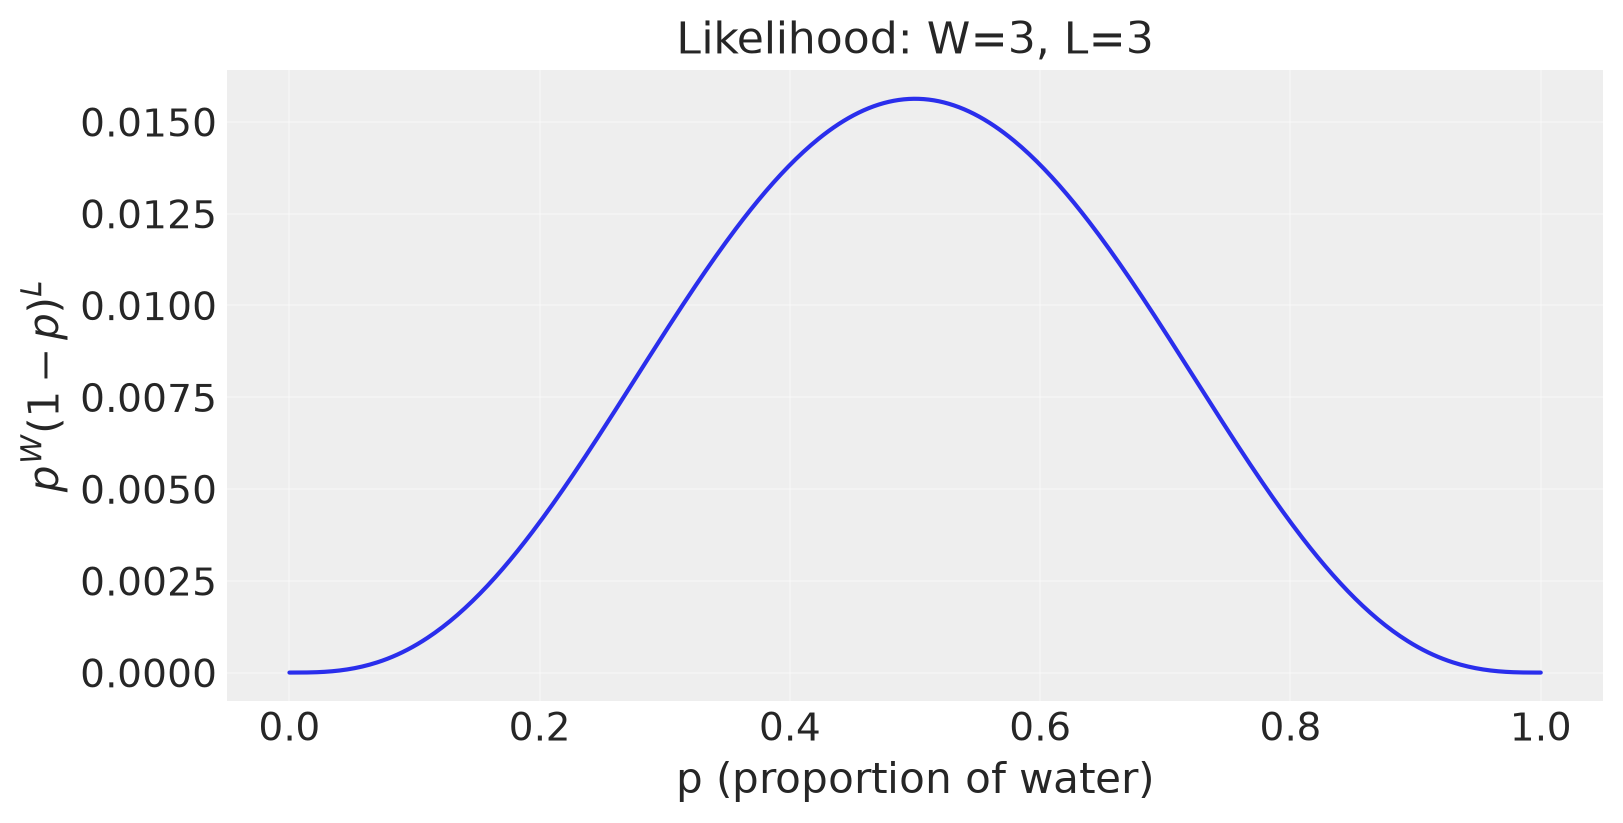

In [62]:
import numpy as np
import matplotlib.pyplot as plt

def plot_likelihood(W, L):
    p = np.linspace(0, 1, 500)
    likelihood = p**W * (1 - p)**L

    plt.figure(figsize=(8, 4))
    plt.plot(p, likelihood)
    plt.xlabel("p (proportion of water)")
    plt.ylabel(r"$p^W(1-p)^L$")
    plt.title(f"Likelihood: W={W}, L={L}")
    plt.grid(alpha=0.3)
    plt.show()

# Example: 6 water, 3 land
plot_likelihood(W=3, L=3)

# integrating this is what converts to probability density
# note density has same shape, but normalizing constant means area under curve sum is 1

The "Beta" distribution

$$
f(p\mid W,L) \text{in other words Posterior probability of p}
=
\underbrace{\frac{(W+L+1)!}{W!\,L!}}_{\text{Normalising constant}}
\quad
\overbrace{p^W(1-p)^L}^{\text{Relative number of ways to observe sample;aka likelihood}}
$$

W -- number times saw water
L -- number times saw land
p -- between 0 and 1

Exact area: 1.0000000000000007
KDE area: 0.9998111881660494
Maximum exact density: 2.7312909617436345
Maximum KDE density: 2.604757039447043


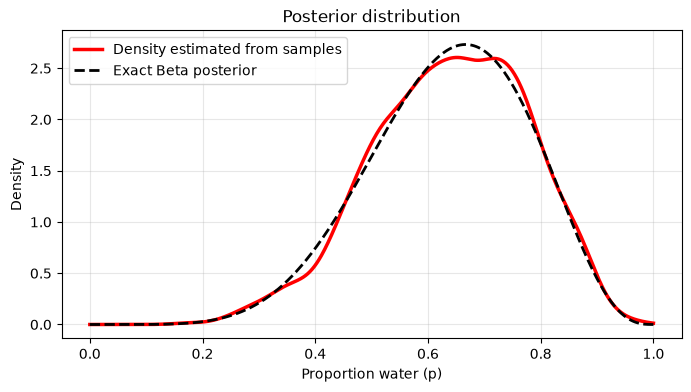

In [3]:
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import gaussian_kde, beta
from scipy.integrate import trapezoid
import util
from importlib import reload
# in case we are editinng
reload(util)

# Observed data
W = 6
L = 3
N = W + L

# Define and sample the Bayesian model
with pm.Model() as model:
    # Uniform prior: Beta(1, 1)
    p = pm.Beta("p", alpha=1, beta=1)

    # Binomial likelihood
    pm.Binomial("W_obs", n=N, p=p, observed=W)

    # Draw posterior samples using MCMC
    idata = util.sample_or_load(
                lambda: pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        random_seed=42
    ), Path("./chap2_1.trace"))

# Extract posterior samples
post_samples = idata.posterior["p"].values.flatten()

# print(post_samples)

# Exact Beta posterior
x = np.linspace(0, 1, 10000)
exact = beta.pdf(x, W+1, L+1)

# KDE estimated from posterior samples
kde = gaussian_kde(post_samples)
estimated = kde(x)

print("Exact area:", trapezoid(exact, x))
print("KDE area:", trapezoid(estimated, x))

print("Maximum exact density:", exact.max())
print("Maximum KDE density:", estimated.max())

# Estimate posterior density from samples (KDE)
density = gaussian_kde(post_samples)

# Values on the x-axis
x = np.linspace(0, 1, 500)

# Plot
plt.figure(figsize=(8, 4))

# Estimated density from posterior samples
plt.plot(
    x, density(x),
    color="red",
    linewidth=2.5,
    label="Density estimated from samples"
)

# Exact analytical posterior: Beta(7, 4)
plt.plot(
    x, beta.pdf(x, W + 1, L + 1),
    "k--",
    linewidth=2,
    label="Exact Beta posterior"
)

plt.xlabel("Proportion water (p)")
plt.ylabel("Density")
plt.title("Posterior distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

$$
\underbrace{f(p\mid W,L)}_{\text{Posterior}}
=
\frac{
\overbrace{P(W,L\mid p)}^{\text{Likelihood}}
\overbrace{f(p)}^{\text{Prior}}
}{
\underbrace{P(W,L)}_{\text{Evidence / normalising constant}}
}
$$

$$
f(p\mid W,L)\propto f(p)P(W,L\mid p)
$$

Note in hastings algorithm, it uses the ratio of prior * likelihood so the normalizing constants cancels out and is not needed.

# https://youtu.be/R1vcdhPBlXA?t=4220

Predictive distribution for p (drawing samples from the posterior distribution with a fixed p, see sim_globe function, this comes from there)

Posterior predictive ( adding them up, so smoother) ; samples from predictive distribution

Looks like it adds 1 for the central prediction in each predictive distribution for p

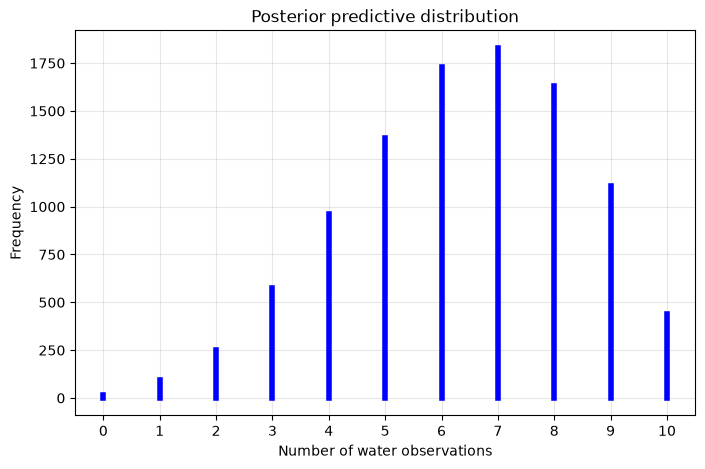

In [6]:
# now we use this sampling trick without pymcc

import numpy as np
import matplotlib.pyplot as plt

# Draw 10,000 samples from the posterior Beta(7, 4)
W = 6
L = 3
num_samples = 10_000
post_samples = np.random.beta(W + 1, L + 1, size=num_samples)

# Simulate 10 globe tosses for each posterior sample
num_tosses = 10
pred_post = np.array([
    np.sum(sim_globe(p, num_tosses) == "W")
    for p in post_samples
])

# Count occurrences of each possible outcome (0 to 10)
tab_post = np.bincount(pred_post, minlength=11)

# Plot the posterior predictive distribution
plt.figure(figsize=(8, 5))

for i in range(11):
    plt.plot(
        [i, i],
        [0, tab_post[i]],
        linewidth=4,
        color="blue"
    )

plt.xlabel("Number of water observations")
plt.ylabel("Frequency")
plt.title("Posterior predictive distribution")
plt.xticks(range(num_tosses+1))
plt.grid(alpha=0.3)
plt.show()

In [20]:
%config InlineBackend.figure_format = 'retina'
RANDOM_SEED = 8927
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-darkgrid")

In [4]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc,arviz,arviz_plots

The watermark extension is already loaded. To reload it, use:
  %reload_ext watermark
Last updated: Sat, 31 Oct 2026

Python implementation: CPython
Python version       : 3.14.4
IPython version      : 9.17.1

pymc       : 6.3.2
arviz      : 1.3.0
arviz_plots: 1.3.2

Watermark: 2.6.0

